# Experiment 8: Multi-Agent Task Allocation and Coordination
**Aim:** To implement a simple multi-agent task allocation system using **Partial Global Planning (PGP)** and the **Contract Net Protocol (CNP)**.

**Scenario:** A *Manager Agent* coordinates *Delivery Agents* that must pick up parcels from shared loading docks and deliver them. Costs are in ₹ (fuel + time).

## Exercise 1: Agent Setup
One Manager Agent, three Delivery Agents (D1, D2, D3) and six delivery tasks, each with a different cost for each agent.

In [1]:
import copy
from dataclasses import dataclass
import pandas as pd
import matplotlib.pyplot as plt

@dataclass
class Task:
    tid: str
    desc: str
    resource: str      # shared loading dock used for pickup
    duration: int      # minutes the agent occupies the dock/task

@dataclass
class Step:
    agent: str
    tid: str
    resource: str
    start: int
    end: int

TASKS = [
    Task("T1", "Deliver electronics to Andheri",   "Dock-1", 30),
    Task("T2", "Deliver furniture to Bandra",      "Dock-1", 25),
    Task("T3", "Deliver groceries to Thane",       "Dock-2", 20),
    Task("T4", "Deliver apparel to Powai",         "Dock-1", 35),
    Task("T5", "Deliver books to Dadar",           "Dock-2", 25),
    Task("T6", "Deliver medicines to Borivali",    "Dock-3", 30),
]

# cost (Rs) for each agent to perform each task
BASE_COSTS = {
    "D1": {"T1": 40, "T2": 70, "T3": 35, "T4": 80, "T5": 45, "T6": 60},
    "D2": {"T1": 55, "T2": 45, "T3": 65, "T4": 50, "T5": 40, "T6": 75},
    "D3": {"T1": 60, "T2": 50, "T3": 30, "T4": 55, "T5": 70, "T6": 35},
}

class DeliveryAgent:
    def __init__(self, name, costs, capacity=3):
        self.name = name
        self.costs = costs
        self.capacity = capacity      # max tasks an agent can take
        self.assigned = []

    def bid(self, task):
        """Return a bid (cost) or None if the agent is at capacity."""
        if len(self.assigned) >= self.capacity:
            return None
        return self.costs[task.tid]

    def award(self, task):
        self.assigned.append(task)

    def total_cost(self):
        return sum(self.costs[t.tid] for t in self.assigned)

def make_agents(costs):
    return [DeliveryAgent(n, c) for n, c in costs.items()]

agents = make_agents(BASE_COSTS)
print("Manager Agent: M0")
print("Delivery Agents:", [a.name for a in agents], "| capacity per agent:", agents[0].capacity)
print("\nTask list:")
display(pd.DataFrame([t.__dict__ for t in TASKS]).set_index("tid"))
print("Cost matrix (Rs): rows = tasks, columns = agents")
display(pd.DataFrame(BASE_COSTS, index=[t.tid for t in TASKS]))

Manager Agent: M0
Delivery Agents: ['D1', 'D2', 'D3'] | capacity per agent: 3

Task list:


,desc,resource,duration
tid,,,
T1,Deliver electronics to Andheri,Dock-1,30
T2,Deliver furniture to Bandra,Dock-1,25
T3,Deliver groceries to Thane,Dock-2,20
T4,Deliver apparel to Powai,Dock-1,35
T5,Deliver books to Dadar,Dock-2,25
T6,Deliver medicines to Borivali,Dock-3,30


Cost matrix (Rs): rows = tasks, columns = agents


,D1,D2,D3
T1,40,55,60
T2,70,45,50
T3,35,65,30
T4,80,50,55
T5,45,40,70
T6,60,75,35


## Exercise 2: PGP Coordination
In PGP every agent first builds a **local plan**. The manager merges them into a **partial global plan**, detects conflicts (two agents using the same dock at the same time) and asks one agent to modify its plan.

Here each agent initially plans to do the tasks that are cheapest for it, starting at t = 0.

=== Step 1: Local plans (before coordination) ===


,agent,tid,resource,start,end
0,D1,T1,Dock-1,0,30
1,D2,T2,Dock-1,0,25
2,D2,T4,Dock-1,25,60
3,D2,T5,Dock-2,60,85
4,D3,T3,Dock-2,0,20
5,D3,T6,Dock-3,20,50


=== Step 2: Conflict detection ===
2 conflict(s) found
  D1:T1 and D2:T2 both use Dock-1 at overlapping times [0-30] / [0-25]
  D1:T1 and D2:T4 both use Dock-1 at overlapping times [0-30] / [25-60]

=== Step 3: Conflict resolution (plan modification) ===
  Round 1: CONFLICT on Dock-1: D1:T1 [0-30] vs D2:T2 [0-25]
           -> D2 modifies plan: T2 delayed by 30 min (now [30-55])

Remaining conflicts: 0


,agent,tid,resource,start,end
0,D1,T1,Dock-1,0,30
1,D2,T2,Dock-1,30,55
2,D2,T4,Dock-1,55,90
3,D2,T5,Dock-2,90,115
4,D3,T3,Dock-2,0,20
5,D3,T6,Dock-3,20,50


Completion time before: 85 min | after resolution: 115 min


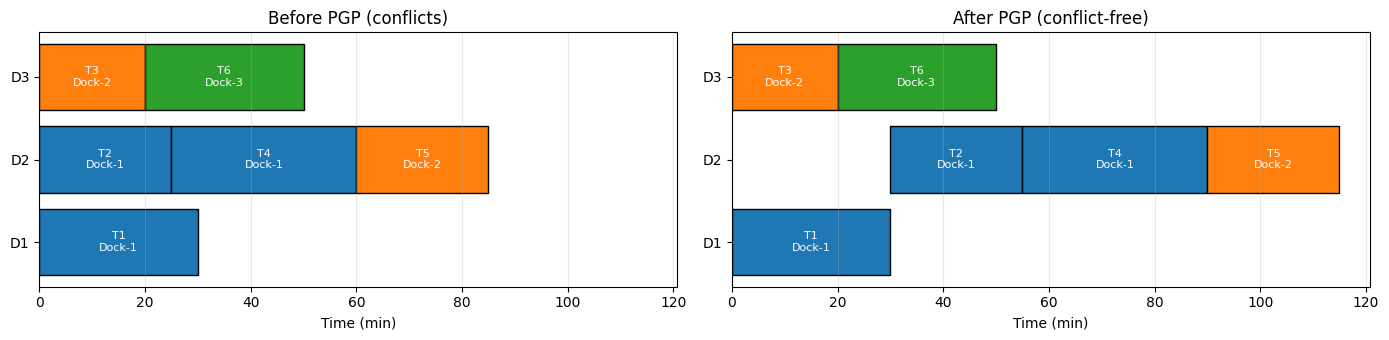

In [2]:
class ManagerAgent:
    def __init__(self, agents, tasks):
        self.agents = agents
        self.tasks = {t.tid: t for t in tasks}
        self.task_list = tasks

    # ---------- PGP ----------
    def make_local_plans(self):
        """Each agent selfishly picks the tasks that are cheapest for it."""
        plans = {a.name: [] for a in self.agents}
        for t in self.task_list:
            best = min(self.agents, key=lambda a: a.costs[t.tid])
            plans[best.name].append(t)
        local = {}
        for name, ts in plans.items():
            clock, steps = 0, []
            for t in ts:
                steps.append(Step(name, t.tid, t.resource, clock, clock + t.duration))
                clock += t.duration
            local[name] = steps
        return local

    def detect_conflicts(self, plans):
        steps = [s for p in plans.values() for s in p]
        conflicts = []
        for i in range(len(steps)):
            for j in range(i + 1, len(steps)):
                a, b = steps[i], steps[j]
                if a.agent != b.agent and a.resource == b.resource \
                        and a.start < b.end and b.start < a.end:
                    conflicts.append((a, b))
        return conflicts

    def resolve_conflicts(self, plans):
        plans = copy.deepcopy(plans)
        round_no = 0
        while True:
            conflicts = self.detect_conflicts(plans)
            if not conflicts:
                break
            round_no += 1
            a, b = conflicts[0]
            # the step that starts later (tie -> later agent name) is the one modified
            first, second = (a, b) if (a.start, a.agent) <= (b.start, b.agent) else (b, a)
            print(f"  Round {round_no}: CONFLICT on {first.resource}: "
                  f"{first.agent}:{first.tid} [{first.start}-{first.end}] vs "
                  f"{second.agent}:{second.tid} [{second.start}-{second.end}]")
            plan = plans[second.agent]
            idx = next(i for i, s in enumerate(plan) if s.tid == second.tid)
            delay = first.end - plan[idx].start
            plan[idx].start += delay
            plan[idx].end += delay
            for k in range(idx + 1, len(plan)):          # push following steps if needed
                if plan[k].start < plan[k - 1].end:
                    d = plan[k - 1].end - plan[k].start
                    plan[k].start += d
                    plan[k].end += d
            print(f"           -> {second.agent} modifies plan: {second.tid} delayed by {delay} min "
                  f"(now [{plan[idx].start}-{plan[idx].end}])")
        return plans

def plans_to_df(plans):
    return pd.DataFrame([s.__dict__ for p in plans.values() for s in p]).sort_values(["agent", "start"]).reset_index(drop=True)

def makespan(plans):
    return max(s.end for p in plans.values() for s in p)

def plot_gantt(plans, title, ax):
    colors = {"Dock-1": "tab:blue", "Dock-2": "tab:orange", "Dock-3": "tab:green"}
    names = sorted(plans)
    for y, n in enumerate(names):
        for s in plans[n]:
            ax.barh(y, s.end - s.start, left=s.start, color=colors[s.resource], edgecolor="black")
            ax.text((s.start + s.end) / 2, y, f"{s.tid}\n{s.resource}", ha="center", va="center", fontsize=8, color="white")
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
    ax.set_xlabel("Time (min)"); ax.set_title(title); ax.grid(axis="x", alpha=0.3)

manager = ManagerAgent(agents, TASKS)

# Step 1: local plans
local_plans = manager.make_local_plans()
print("=== Step 1: Local plans (before coordination) ===")
display(plans_to_df(local_plans))

# Step 2: detect conflicts in the partial global plan
print("=== Step 2: Conflict detection ===")
conflicts = manager.detect_conflicts(local_plans)
print(f"{len(conflicts)} conflict(s) found")
for a, b in conflicts:
    print(f"  {a.agent}:{a.tid} and {b.agent}:{b.tid} both use {a.resource} "
          f"at overlapping times [{a.start}-{a.end}] / [{b.start}-{b.end}]")

# Step 3: resolve
print("\n=== Step 3: Conflict resolution (plan modification) ===")
resolved_plans = manager.resolve_conflicts(local_plans)
print("\nRemaining conflicts:", len(manager.detect_conflicts(resolved_plans)))
display(plans_to_df(resolved_plans))
print(f"Completion time before: {makespan(local_plans)} min | after resolution: {makespan(resolved_plans)} min")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), sharex=True)
plot_gantt(local_plans, "Before PGP (conflicts)", axes[0])
plot_gantt(resolved_plans, "After PGP (conflict-free)", axes[1])
plt.tight_layout(); plt.show()

## Exercise 3: CNP Task Allocation
Contract Net Protocol: **Task Announcement → Bidding → Bid Comparison → Agent Selection → Task Assignment.**
First a detailed walk-through of a single task (T1).

In [3]:
def run_cnp_task(manager, task, verbose=True):
    """Run the 5 CNP phases for one task. Returns (selected_agent, cost)."""
    # 1. Task announcement
    if verbose: print(f"[1] ANNOUNCEMENT : Manager announces {task.tid} ({task.desc}, {task.resource})")
    # 2. Bidding
    bids = {}
    for a in manager.agents:
        b = a.bid(task)
        bids[a.name] = b
        if verbose: print(f"[2] BIDDING      : {a.name} bids " + (f"Rs {b}" if b is not None else "-- (at capacity, no bid)"))
    valid = {n: b for n, b in bids.items() if b is not None}
    if not valid:
        raise RuntimeError(f"No agent can take {task.tid}")
    # 3. Bid comparison (lowest bid wins; tie -> lighter load, then name)
    load = {a.name: len(a.assigned) for a in manager.agents}
    winner = min(valid, key=lambda n: (valid[n], load[n], n))
    if verbose: print(f"[3] COMPARISON   : lowest bid = Rs {valid[winner]}")
    # 4. Agent selection
    if verbose: print(f"[4] SELECTION    : {winner} selected")
    # 5. Task assignment
    next(a for a in manager.agents if a.name == winner).award(task)
    if verbose: print(f"[5] ASSIGNMENT   : {task.tid} awarded to {winner} at Rs {valid[winner]}\n")
    return winner, valid[winner]

demo_agents = make_agents(BASE_COSTS)
demo_manager = ManagerAgent(demo_agents, TASKS)
print("--- Detailed CNP walk-through for T1 ---")
run_cnp_task(demo_manager, TASKS[0], verbose=True)

--- Detailed CNP walk-through for T1 ---


[1] ANNOUNCEMENT : Manager announces T1 (Deliver electronics to Andheri, Dock-1)
[2] BIDDING      : D1 bids Rs 40
[2] BIDDING      : D2 bids Rs 55
[2] BIDDING      : D3 bids Rs 60
[3] COMPARISON   : lowest bid = Rs 40
[4] SELECTION    : D1 selected
[5] ASSIGNMENT   : T1 awarded to D1 at Rs 40



('D1', 40)

## Exercise 4: Multiple Task Allocation
All six tasks are announced one after another and allocated automatically from the bids. Final allocation and total cost are shown below.

In [4]:
def run_cnp_all(costs, verbose=False):
    ags = make_agents(costs)
    mgr = ManagerAgent(ags, TASKS)
    rows = []
    for t in TASKS:
        agent, cost = run_cnp_task(mgr, t, verbose=verbose)
        rows.append({"Task": t.tid, "Selected Agent": agent, "Cost/Time": cost})
    df = pd.DataFrame(rows)
    per_agent = {a.name: a.total_cost() for a in ags}
    return df, per_agent

print("=== Full CNP run (all tasks, detailed log) ===\n")
alloc_base, totals_base = run_cnp_all(BASE_COSTS, verbose=True)

print("=== FINAL ALLOCATION (Original costs) ===")
display(alloc_base.set_index("Task"))
print(f"TOTAL COST = Rs {alloc_base['Cost/Time'].sum()}")
print("Total assigned cost per agent:", totals_base)

=== Full CNP run (all tasks, detailed log) ===

[1] ANNOUNCEMENT : Manager announces T1 (Deliver electronics to Andheri, Dock-1)
[2] BIDDING      : D1 bids Rs 40
[2] BIDDING      : D2 bids Rs 55
[2] BIDDING      : D3 bids Rs 60
[3] COMPARISON   : lowest bid = Rs 40
[4] SELECTION    : D1 selected
[5] ASSIGNMENT   : T1 awarded to D1 at Rs 40

[1] ANNOUNCEMENT : Manager announces T2 (Deliver furniture to Bandra, Dock-1)
[2] BIDDING      : D1 bids Rs 70
[2] BIDDING      : D2 bids Rs 45
[2] BIDDING      : D3 bids Rs 50
[3] COMPARISON   : lowest bid = Rs 45
[4] SELECTION    : D2 selected
[5] ASSIGNMENT   : T2 awarded to D2 at Rs 45

[1] ANNOUNCEMENT : Manager announces T3 (Deliver groceries to Thane, Dock-2)
[2] BIDDING      : D1 bids Rs 35
[2] BIDDING      : D2 bids Rs 65
[2] BIDDING      : D3 bids Rs 30
[3] COMPARISON   : lowest bid = Rs 30
[4] SELECTION    : D3 selected
[5] ASSIGNMENT   : T3 awarded to D3 at Rs 30

[1] ANNOUNCEMENT : Manager announces T4 (Deliver apparel to Powai, Dock-1)

,Selected Agent,Cost/Time
Task,,
T1,D1,40
T2,D2,45
T3,D3,30
T4,D2,50
T5,D2,40
T6,D3,35


TOTAL COST = Rs 240
Total assigned cost per agent: {'D1': 40, 'D2': 135, 'D3': 65}


## Exercise 5: Modification & Visualization
We change the costs: D2 becomes more expensive (fuel surge on T2 and T4) and D1 becomes cheaper for T4 and T6 (new bike for D1). Then CNP is re-run and compared.

Changed costs (old -> new):
  D1 / T4: 80 -> 48
  D1 / T6: 60 -> 38
  D2 / T2: 45 -> 55
  D2 / T4: 50 -> 90
  D2 / T5: 40 -> 42

=== CNP re-run with modified costs ===

[1] ANNOUNCEMENT : Manager announces T1 (Deliver electronics to Andheri, Dock-1)
[2] BIDDING      : D1 bids Rs 40
[2] BIDDING      : D2 bids Rs 55
[2] BIDDING      : D3 bids Rs 60
[3] COMPARISON   : lowest bid = Rs 40
[4] SELECTION    : D1 selected
[5] ASSIGNMENT   : T1 awarded to D1 at Rs 40

[1] ANNOUNCEMENT : Manager announces T2 (Deliver furniture to Bandra, Dock-1)
[2] BIDDING      : D1 bids Rs 70
[2] BIDDING      : D2 bids Rs 55
[2] BIDDING      : D3 bids Rs 50
[3] COMPARISON   : lowest bid = Rs 50
[4] SELECTION    : D3 selected
[5] ASSIGNMENT   : T2 awarded to D3 at Rs 50

[1] ANNOUNCEMENT : Manager announces T3 (Deliver groceries to Thane, Dock-2)
[2] BIDDING      : D1 bids Rs 35
[2] BIDDING      : D2 bids Rs 65
[2] BIDDING      : D3 bids Rs 30
[3] COMPARISON   : lowest bid = Rs 30
[4] SELECTION    : D3 selected

,Selected Agent,Cost/Time
Task,,
T1,D1,40
T2,D3,50
T3,D3,30
T4,D1,48
T5,D2,42
T6,D3,35


TOTAL COST = Rs 245
Total assigned cost per agent: {'D1': 88, 'D2': 42, 'D3': 115}

=== Comparison ===


,Agent (original),Cost (original),Agent (modified),Cost (modified),Agent changed?
Task,,,,,
T1,D1,40,D1,40,False
T2,D2,45,D3,50,True
T3,D3,30,D3,30,False
T4,D2,50,D1,48,True
T5,D2,40,D2,42,False
T6,D3,35,D3,35,False


Total cost: original = Rs 240 | modified = Rs 245


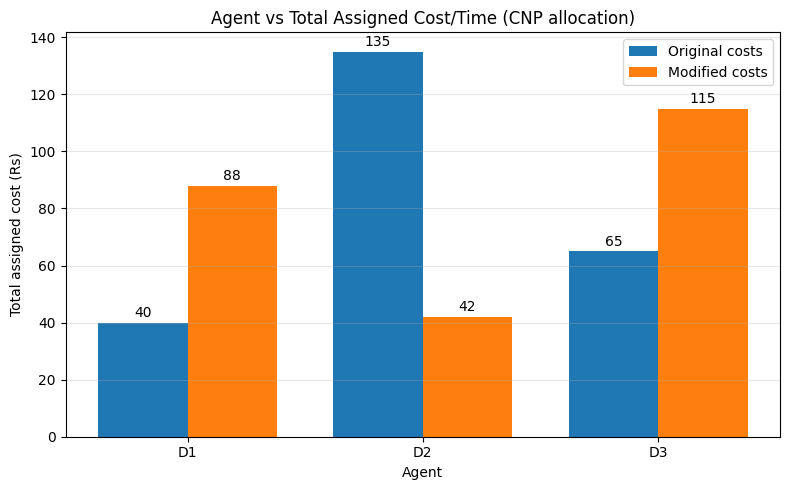

In [5]:
MOD_COSTS = copy.deepcopy(BASE_COSTS)
MOD_COSTS["D2"]["T2"] = 55   # 45 -> 55
MOD_COSTS["D2"]["T4"] = 90   # 50 -> 90
MOD_COSTS["D2"]["T5"] = 42   # 40 -> 42
MOD_COSTS["D1"]["T4"] = 48   # 80 -> 48
MOD_COSTS["D1"]["T6"] = 38   # 60 -> 38

print("Changed costs (old -> new):")
for ag in BASE_COSTS:
    for t in BASE_COSTS[ag]:
        if BASE_COSTS[ag][t] != MOD_COSTS[ag][t]:
            print(f"  {ag} / {t}: {BASE_COSTS[ag][t]} -> {MOD_COSTS[ag][t]}")

print("\n=== CNP re-run with modified costs ===\n")
alloc_mod, totals_mod = run_cnp_all(MOD_COSTS, verbose=True)

print("=== FINAL ALLOCATION (Modified costs) ===")
display(alloc_mod.set_index("Task"))
print(f"TOTAL COST = Rs {alloc_mod['Cost/Time'].sum()}")
print("Total assigned cost per agent:", totals_mod)

# ---- comparison ----
cmp = pd.DataFrame({
    "Task": alloc_base["Task"],
    "Agent (original)": alloc_base["Selected Agent"], "Cost (original)": alloc_base["Cost/Time"],
    "Agent (modified)": alloc_mod["Selected Agent"],  "Cost (modified)": alloc_mod["Cost/Time"],
})
cmp["Agent changed?"] = cmp["Agent (original)"] != cmp["Agent (modified)"]
print("\n=== Comparison ===")
display(cmp.set_index("Task"))
print(f"Total cost: original = Rs {alloc_base['Cost/Time'].sum()} | modified = Rs {alloc_mod['Cost/Time'].sum()}")

# ---- plots: Agent vs Total Assigned Cost ----
names = list(BASE_COSTS)
x = range(len(names)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar([i - w/2 for i in x], [totals_base[n] for n in names], w, label="Original costs", color="tab:blue")
b2 = ax.bar([i + w/2 for i in x], [totals_mod[n] for n in names], w, label="Modified costs", color="tab:orange")
ax.bar_label(b1, padding=2); ax.bar_label(b2, padding=2)
ax.set_xticks(list(x)); ax.set_xticklabels(names)
ax.set_xlabel("Agent"); ax.set_ylabel("Total assigned cost (Rs)")
ax.set_title("Agent vs Total Assigned Cost/Time (CNP allocation)")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## Observations

**PGP (conflict resolution)**
- Every agent's local plan looked fine on its own, but the merged partial global plan showed D1 (T1) and D2 (T2, T4) using **Dock-1** at overlapping times.
- The manager detected both overlaps and asked D2 to modify its plan. Delaying T2 by 30 min (and pushing T4, T5 after it) removed all conflicts in one round.
- Cost of coordination: the completion time grew from 85 min to 115 min, but the plan became feasible.

**CNP (task allocation)**
- For each task the manager announced, collected bids, compared them, selected the lowest bidder and assigned the task.
- With original costs, the total cost was Rs 240 (D1 = 40, D2 = 135, D3 = 65). D2 reached its capacity of 3 tasks, so it did not bid on T6 and D3 won it.

**Effect of changing the input**
- Raising D2's costs and lowering D1's changed the winners of T2 (D2 -> D3) and T4 (D2 -> D1); T1, T3, T5, T6 stayed the same.
- The total cost moved from Rs 240 to Rs 245. D2's load dropped from Rs 135 to Rs 42 and D3's rose from Rs 65 to Rs 115.
- CNP allocates greedily, task by task, so it gives a good but not guaranteed globally optimal allocation, and the order of announcement and agent capacity can influence the result.